In [2]:
import networkx as nx

G=nx.Graph()  #create graph it is empty

G.add_nodes_from(["A","B","C","D","F"])


G.add_edge(
    "A", "B",
    distance=5,
    speed_limit=60,
    road_type="Highway"
)

G.add_edge(
    "A", "C",
    distance=2,
    speed_limit=30,
    road_type="Street"
)

G.add_edge(
    "B", "D",
    distance=3,
    speed_limit=80,
    road_type="Highway"
)

G.add_edge(
    "C", "D",
    distance=4,
    speed_limit=40,
    road_type="Residential"
)
G.add_edge(
    "B","C",
    distance=6,
    speed_limit=50,
    road_type="Main road"
)
G.add_edge(
    "A","F",
    distance=8,
    speed_limit=50,
    road_type="canal road"
)
#print("Nodes:",G.nodes())

#print("\nEdges:",G.edges(data=True))

path=nx.shortest_path(
    G,
    source="A",
    target="D",
    weight="distance"

)
print("\n shortest path:",path)

#calc travel time

for u,v,data in G.edges(data=True):
    d=data["distance"]
    s=data["speed_limit"] 
    t=d/s

    data["travel_time"]=t

for u, v, data in G.edges(data=True):
    print(u, v, data)




 shortest path: ['A', 'C', 'D']
A B {'distance': 5, 'speed_limit': 60, 'road_type': 'Highway', 'travel_time': 0.08333333333333333}
A C {'distance': 2, 'speed_limit': 30, 'road_type': 'Street', 'travel_time': 0.06666666666666667}
A F {'distance': 8, 'speed_limit': 50, 'road_type': 'canal road', 'travel_time': 0.16}
B D {'distance': 3, 'speed_limit': 80, 'road_type': 'Highway', 'travel_time': 0.0375}
B C {'distance': 6, 'speed_limit': 50, 'road_type': 'Main road', 'travel_time': 0.12}
C D {'distance': 4, 'speed_limit': 40, 'road_type': 'Residential', 'travel_time': 0.1}


In [3]:
import pandas as pd
roads=pd.read_csv("../data/roads.csv")

In [4]:
roads.head()

,source,destination,distance,speed_limit,road_type
0,A,B,5,60,Highway
1,A,C,2,30,Street
2,B,D,3,80,Highway
3,C,D,4,40,Residential
4,B,C,6,50,Main Road


In [5]:
roads.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   source       5 non-null      str  
 1   destination  5 non-null      str  
 2   distance     5 non-null      int64
 3   speed_limit  5 non-null      int64
 4   road_type    5 non-null      str  
dtypes: int64(2), str(3)
memory usage: 382.0 bytes


In [6]:
roads.describe()

,distance,speed_limit
count,5.000000,5.000000
mean,4.000000,52.000000
std,1.581139,19.235384
min,2.000000,30.000000
25%,3.000000,40.000000
50%,4.000000,50.000000
75%,5.000000,60.000000
max,6.000000,80.000000


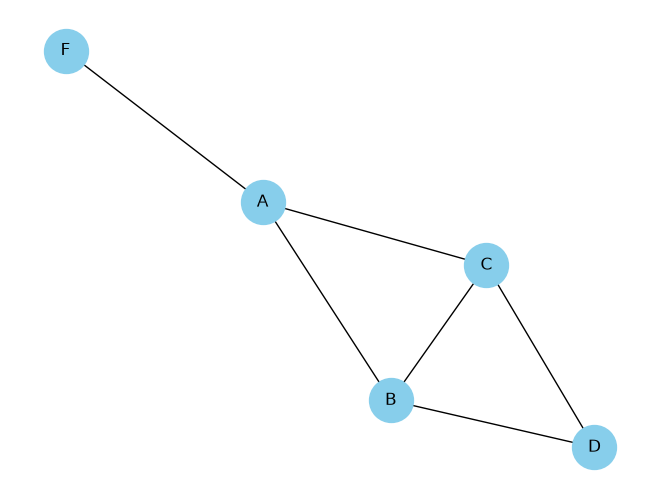

In [7]:
import matplotlib.pyplot as plt

nx.draw(G, with_labels=True, node_color="skyblue", node_size=1000)
plt.show()


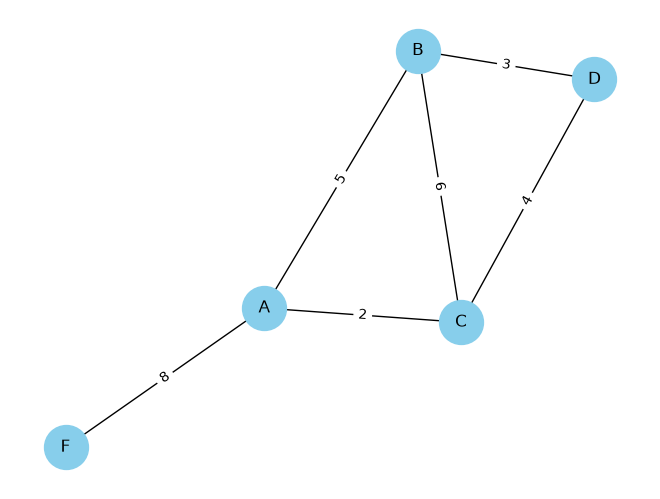

In [8]:
import matplotlib.pyplot as plt

# 1. Position the nodes and draw the simple network
pos = nx.spring_layout(G)
nx.draw(G, pos, with_labels=True, node_color="skyblue", node_size=1000)

# 2. Pull the distance numbers and print them on the lines
labels = nx.get_edge_attributes(G, 'distance')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

plt.show()


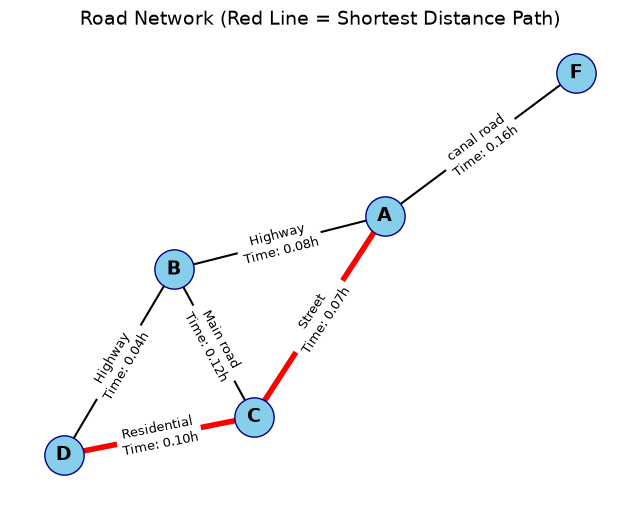

In [9]:
import matplotlib.pyplot as plt

# 1. Compute positions for the nodes so they spread out nicely
pos = nx.spring_layout(G, seed=42)  # seed keeps the layout consistent

# 2. Identify which edges belong to the shortest path
# path is ['A', 'C', 'D'], so path_edges will be [('A', 'C'), ('C', 'D')]
path_edges = list(zip(path, path[1:]))

# 3. Create lists for edge styling (Red for shortest path, Black for others)
edge_colors = ["red" if (u, v) in path_edges or (v, u) in path_edges else "black" for u, v in G.edges()]
edge_widths = [4 if (u, v) in path_edges or (v, u) in path_edges else 1.5 for u, v in G.edges()]

# 4. Draw the base components (Nodes, Labels, and Edges)
plt.figure(figsize=(8, 6))

nx.draw_networkx_nodes(G, pos, node_size=800, node_color="skyblue", edgecolors="navy")
nx.draw_networkx_labels(G, pos, font_size=14, font_weight="bold")
nx.draw_networkx_edges(G, pos, edge_color=edge_colors, width=edge_widths)

# 5. Create and draw descriptive labels for the edges (Road Type & Travel Time)
edge_labels = {
    (u, v): f"{data['road_type']}\nTime: {data['travel_time']:.2f}h" 
    for u, v, data in G.edges(data=True)
}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=9)

# 6. Render the graph window
plt.title("Road Network (Red Line = Shortest Distance Path)", fontsize=14)
plt.axis("off")  # Turn off the axis grid lines
plt.show()


In [10]:
roads.isnull().sum()

source         0
destination    0
distance       0
speed_limit    0
road_type      0
dtype: int64

In [11]:
road_graph = nx.Graph()

for _, row in roads.iterrows():

    road_graph.add_edge(
        row["source"],
        row["destination"],
        distance=row["distance"],
        speed_limit=row["speed_limit"],
        road_type=row["road_type"]
    )

In [12]:
print(road_graph.nodes())

['A', 'B', 'C', 'D']


In [13]:
print("Nodes:")
print(road_graph.nodes())

print("\nEdges:")

for u, v, data in road_graph.edges(data=True):
    print(f"{u} --> {v}")
    print(data)
    print("-" * 30)

Nodes:
['A', 'B', 'C', 'D']

Edges:
A --> B
{'distance': 5, 'speed_limit': 60, 'road_type': 'Highway'}
------------------------------
A --> C
{'distance': 2, 'speed_limit': 30, 'road_type': 'Street'}
------------------------------
B --> D
{'distance': 3, 'speed_limit': 80, 'road_type': 'Highway'}
------------------------------
B --> C
{'distance': 6, 'speed_limit': 50, 'road_type': 'Main Road'}
------------------------------
C --> D
{'distance': 4, 'speed_limit': 40, 'road_type': 'Residential'}
------------------------------


AttributeError: 'DataFrame' object has no attribute 'is_directed'

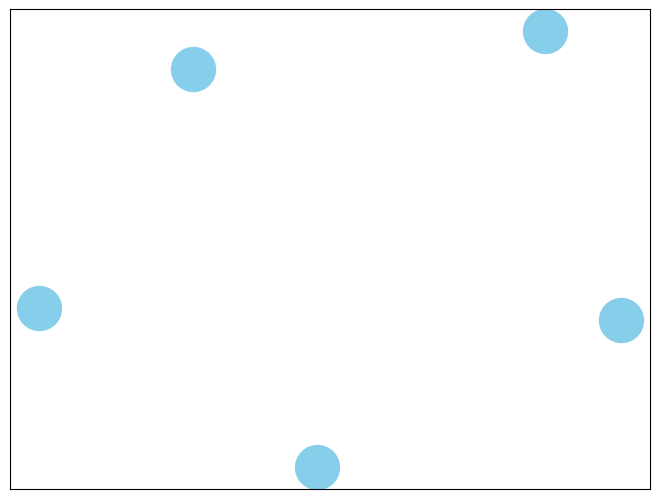

In [14]:
#draw graph imported by pandas

nx.draw(roads, with_labels=True, node_color="skyblue", node_size=1000)

   source destination  distance  speed_limit    road_type
0       A           B         5           60      Highway
1       A           C         3           40       Street
2       A           D         4           50    Main Road
3       B           E         6           80      Highway
4       B           F         3           50       Street
5       C           D         2           30  Residential
6       C           G         5           40       Street
7       D           G         4           60    Main Road
8       D           H         6           80      Highway
9       E           F         2           40  Residential
10      E           I         5           60    Main Road
11      F           G         3           50       Street
12      F           J         7           80      Highway
13      G           H         2           30  Residential
14      G           J         4           60    Main Road
15      H           K         5           80      Highway
16      I     

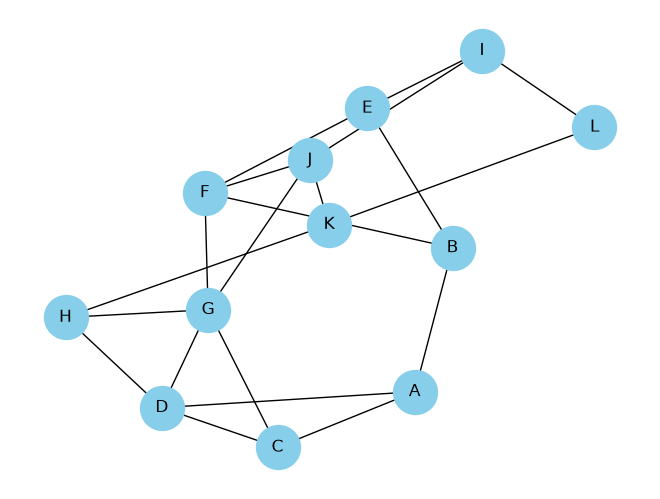

In [136]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# 1. Read the CSV file into a Pandas DataFrame
df_roads = pd.read_csv("../data/roads.csv")
print(df_roads)

# 2. Convert the Pandas DataFrame into a NetworkX Graph (Fixed typo)
G = nx.from_pandas_edgelist(
    df_roads,
    source="source",
    target="destination",
    edge_attr=True
)

# 3. Your exact drawing code
nx.draw(G, with_labels=True, node_color="skyblue", node_size=1000)
plt.show()


In [137]:
#EDA
roads.head()

,source,destination,distance,speed_limit,road_type
0,A,B,5,60,Highway
1,A,C,3,40,Street
2,A,D,4,50,Main Road
3,B,E,6,80,Highway
4,B,F,3,50,Street


In [138]:
df_roads.head()

,source,destination,distance,speed_limit,road_type
0,A,B,5,60,Highway
1,A,C,3,40,Street
2,A,D,4,50,Main Road
3,B,E,6,80,Highway
4,B,F,3,50,Street


In [18]:
df_roads.shape

(5, 5)

In [19]:
roads.shape

(5, 5)

In [20]:
roads.columns


Index(['source', 'destination', 'distance', 'speed_limit', 'road_type'], dtype='str')

In [21]:
df_roads["road_type"].value_counts()

road_type
Highway        2
Street         1
Residential    1
Main Road      1
Name: count, dtype: int64

In [22]:
df_roads["speed_limit"].value_counts()

speed_limit
60    1
30    1
80    1
40    1
50    1
Name: count, dtype: int64

In [23]:
df_roads["distance"].value_counts()

distance
5    1
2    1
3    1
4    1
6    1
Name: count, dtype: int64

In [24]:
print("Average Speed Limit:", roads["speed_limit"].mean())

Average Speed Limit: 52.0


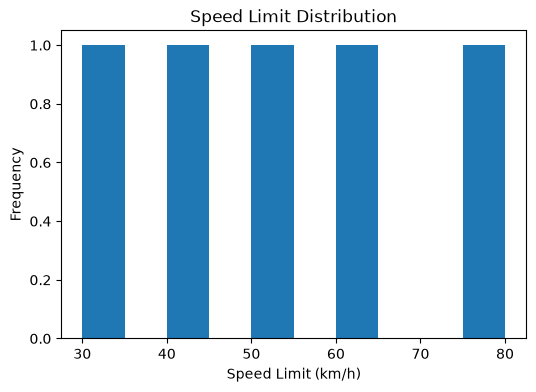

In [25]:
plt.figure(figsize=(6,4))

plt.hist(
    roads["speed_limit"],
    
)

plt.title("Speed Limit Distribution")

plt.xlabel("Speed Limit (km/h)")

plt.ylabel("Frequency")

plt.show()

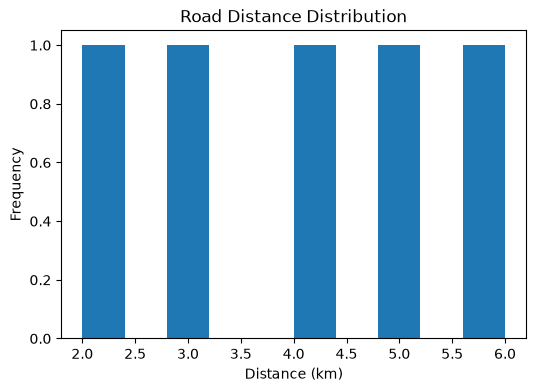

In [27]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))

plt.hist(
    roads["distance"],
    
)

plt.title("Road Distance Distribution")

plt.xlabel("Distance (km)")

plt.ylabel("Frequency")

plt.show()

In [28]:
traffic=pd.read_csv("../data/raw/traffic_data.csv")

In [29]:
traffic.head()

,road_id,hour_of_day,day_of_week,avg_speed_kmph,source_node,destination_node,distance_km,road_type,speed_limit_kmph,travel_time_min
0,1,0,0,111.05,6,3,1.44,Street,100,0.778028
1,1,0,1,109.24,6,3,1.44,Street,100,0.790919
2,1,0,2,111.30,6,3,1.44,Street,100,0.776280
3,1,0,3,119.18,6,3,1.44,Street,100,0.724954
4,1,0,4,105.88,6,3,1.44,Street,100,0.816018


In [30]:
traffic

,road_id,hour_of_day,day_of_week,avg_speed_kmph,source_node,destination_node,distance_km,road_type,speed_limit_kmph,travel_time_min
0,1,0,0,111.05,6,3,1.44,Street,100,0.778028
1,1,0,1,109.24,6,3,1.44,Street,100,0.790919
2,1,0,2,111.30,6,3,1.44,Street,100,0.776280
3,1,0,3,119.18,6,3,1.44,Street,100,0.724954
4,1,0,4,105.88,6,3,1.44,Street,100,0.816018
...,...,...,...,...,...,...,...,...,...,...
9067,60,23,2,58.08,9,18,11.20,Highway,80,11.570248
9068,60,23,3,76.97,9,18,11.20,Highway,80,8.730674
9069,60,23,4,72.33,9,18,11.20,Highway,80,9.290751
9070,60,23,5,66.78,9,18,11.20,Highway,80,10.062893


In [31]:
traffic.shape

(9072, 10)

In [32]:
traffic.columns

Index(['road_id', 'hour_of_day', 'day_of_week', 'avg_speed_kmph',
       'source_node', 'destination_node', 'distance_km', 'road_type',
       'speed_limit_kmph', 'travel_time_min'],
      dtype='str')

In [33]:
traffic.dtypes


road_id               int64
hour_of_day           int64
day_of_week           int64
avg_speed_kmph      float64
source_node           int64
destination_node      int64
distance_km         float64
road_type               str
speed_limit_kmph      int64
travel_time_min     float64
dtype: object

In [34]:
traffic.isnull().sum()

road_id             0
hour_of_day         0
day_of_week         0
avg_speed_kmph      0
source_node         0
destination_node    0
distance_km         0
road_type           0
speed_limit_kmph    0
travel_time_min     0
dtype: int64

In [35]:
traffic.columns


Index(['road_id', 'hour_of_day', 'day_of_week', 'avg_speed_kmph',
       'source_node', 'destination_node', 'distance_km', 'road_type',
       'speed_limit_kmph', 'travel_time_min'],
      dtype='str')

In [36]:
traffic["road_type"].value_counts()
traffic["day_of_week"].value_counts()

day_of_week
0    1296
1    1296
2    1296
3    1296
4    1296
5    1296
6    1296
Name: count, dtype: int64

In [37]:
# Features
x = traffic[
    [
        "hour_of_day",
        "day_of_week",
        "distance_km",
        "road_type",
        "speed_limit_kmph"
    ]
]

# Target
y = traffic["avg_speed_kmph"]

In [38]:
x.head()

,hour_of_day,day_of_week,distance_km,road_type,speed_limit_kmph
0,0,0,1.44,Street,100
1,0,1,1.44,Street,100
2,0,2,1.44,Street,100
3,0,3,1.44,Street,100
4,0,4,1.44,Street,100


In [39]:
y.head()

0    111.05
1    109.24
2    111.30
3    119.18
4    105.88
Name: avg_speed_kmph, dtype: float64

In [40]:
#one hot encoding
x=pd.get_dummies(
    x,
    columns=["road_type"],
    dtype=int
)

In [41]:
x.head()

,hour_of_day,day_of_week,distance_km,speed_limit_kmph,road_type_Highway,road_type_Main road,road_type_Residential,road_type_Street
0,0,0,1.44,100,0,0,0,1
1,0,1,1.44,100,0,0,0,1
2,0,2,1.44,100,0,0,0,1
3,0,3,1.44,100,0,0,0,1
4,0,4,1.44,100,0,0,0,1


In [42]:
x.columns

Index(['hour_of_day', 'day_of_week', 'distance_km', 'speed_limit_kmph',
       'road_type_Highway', 'road_type_Main road', 'road_type_Residential',
       'road_type_Street'],
      dtype='str')

In [43]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)  #randomstate is used to produce same split
print("Training Features:", x_train.shape)
print("Testing Features:", x_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (7257, 8)
Testing Features: (1815, 8)
Training Target: (7257,)
Testing Target: (1815,)


In [46]:
from sklearn.tree import DecisionTreeRegressor
model = DecisionTreeRegressor(
    random_state=42
)
#fit means xtrain and y train learn 
model.fit(
    x_train,
    y_train
)
predictions=model.predict(
    x_test
)
print(model)
print(predictions[:10])
comparision=pd.DataFrame({
    "Actual":y_test.values,
    "Predicted":predictions
})

DecisionTreeRegressor(random_state=42)
[ 58.88  87.18  26.26  25.5   44.99  53.02  24.17 124.47  93.85  37.91]


In [47]:
#compare
comparision.head()

,Actual,Predicted
0,57.65,58.88
1,96.13,87.18
2,25.34,26.26
3,28.68,25.50
4,44.54,44.99


In [48]:

#regression model so we are importing the regression metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


In [49]:
#MAE:tells us the average error between the predicted speed and the actual speed (lowerr is better)
mae=mean_absolute_error(
    y_test,
    predictions
)
print("MAE:",mae)

MAE: 5.809851239669421


In [50]:
#MSE:
mse = mean_squared_error(
    y_test,
    predictions
)

print("MSE:", mse)

MSE: 58.999492121212114


In [51]:
#RMSE:
import numpy as np
rmse = np.sqrt(mse)

print("RMSE:", rmse)

RMSE: 7.681112687704309


In [52]:
#R2 score:measures how much of the variation in the target is explained by the model
r2 = r2_score(
    y_test,
    predictions
)

print("R² Score:", r2)

R² Score: 0.9109787239771674


In [53]:
print("Model Evaluation")
print("-" * 30)
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.3f}")

Model Evaluation
------------------------------
MAE  : 5.81
MSE  : 59.00
RMSE : 7.68
R²   : 0.911


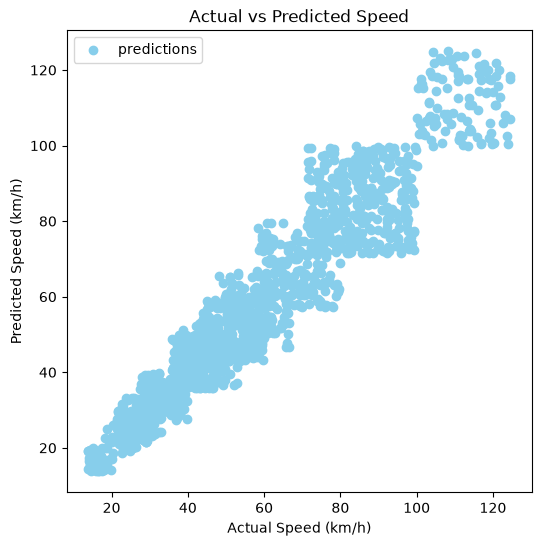

In [54]:
#visualize
plt.figure(figsize=(6,6))
plt.scatter(y_test,predictions,c="skyblue",label="predictions")

plt.xlabel("Actual Speed (km/h)")
plt.ylabel("Predicted Speed (km/h)")
plt.title("Actual vs Predicted Speed")
plt.legend()
plt.show()

In [55]:
feature_names = x.columns

In [56]:
def predict_speed(
    model,feature_names,
    hour_of_day,day_of_week,distance_km,
    road_type, speed_limit_kmph
):

    # Create one-row DataFrame
    sample = pd.DataFrame({
        "hour_of_day": [hour_of_day],
        "day_of_week": [day_of_week],
        "distance_km": [distance_km],
        "road_type": [road_type],
        "speed_limit_kmph": [speed_limit_kmph]
    })

    # One-hot encode
    sample = pd.get_dummies(
        sample,
        columns=["road_type"]
    )

    # Match training columns
    sample = sample.reindex(
        columns=feature_names,
        fill_value=0
    )

    # Predict
    prediction = model.predict(sample)

    return prediction[0]

In [57]:
speed = predict_speed(
    model=model,
    feature_names=feature_names,
    hour_of_day=9,
    day_of_week=2,
    distance_km=5,
    road_type="Highway",
    speed_limit_kmph=80
)

print(f"Predicted Speed: {speed:.2f} km/h")

Predicted Speed: 37.00 km/h


In [58]:
#find the shortest path
path = nx.shortest_path(
    road_graph,
    source="A",
    target="D",
    weight="distance"
)

print(path)

['A', 'C', 'D']


In [59]:
#short path distance
distance = nx.shortest_path_length(
    road_graph,
    source="A",
    target="D",
    weight="distance"
)

print(distance)


6


KeyError: 'travel_time'

In [61]:
for u, v, data in G.edges(data=True):
    print(u, v, data)

A B {'distance': 5, 'speed_limit': 60, 'road_type': 'Highway'}
A C {'distance': 2, 'speed_limit': 30, 'road_type': 'Street'}
B D {'distance': 3, 'speed_limit': 80, 'road_type': 'Highway'}
B C {'distance': 6, 'speed_limit': 50, 'road_type': 'Main Road'}
C D {'distance': 4, 'speed_limit': 40, 'road_type': 'Residential'}


In [62]:
G.edges(data=True)

EdgeDataView([('A', 'B', {'distance': 5, 'speed_limit': 60, 'road_type': 'Highway'}), ('A', 'C', {'distance': 2, 'speed_limit': 30, 'road_type': 'Street'}), ('B', 'D', {'distance': 3, 'speed_limit': 80, 'road_type': 'Highway'}), ('B', 'C', {'distance': 6, 'speed_limit': 50, 'road_type': 'Main Road'}), ('C', 'D', {'distance': 4, 'speed_limit': 40, 'road_type': 'Residential'})])

In [63]:
df_roads

,source,destination,distance,speed_limit,road_type
0,A,B,5,60,Highway
1,A,C,2,30,Street
2,B,D,3,80,Highway
3,C,D,4,40,Residential
4,B,C,6,50,Main Road


In [64]:
for u,v,data in G.edges(data=True):
    data["travel_time"]=data["distance"]/data["speed_limit"]

In [65]:
G.nodes

NodeView(('A', 'B', 'C', 'D'))

In [67]:
#my dijsktra
from dijkstra import dijkstra

path, cost = dijkstra(G, "A", "D")

print(path)
print(cost)

['A', 'B', 'D']
0.12083333333333332


In [68]:
#networkx
import networkx as nx

nx_path = nx.dijkstra_path(
    G,
    source="A",
    target="D",
    weight="travel_time"
)

nx_cost = nx.dijkstra_path_length(
    G,
    source="A",
    target="D",
    weight="travel_time"
)

print("NetworkX")
print("Path:", nx_path)
print("Cost:", nx_cost)

NetworkX
Path: ['A', 'B', 'D']
Cost: 0.12083333333333332


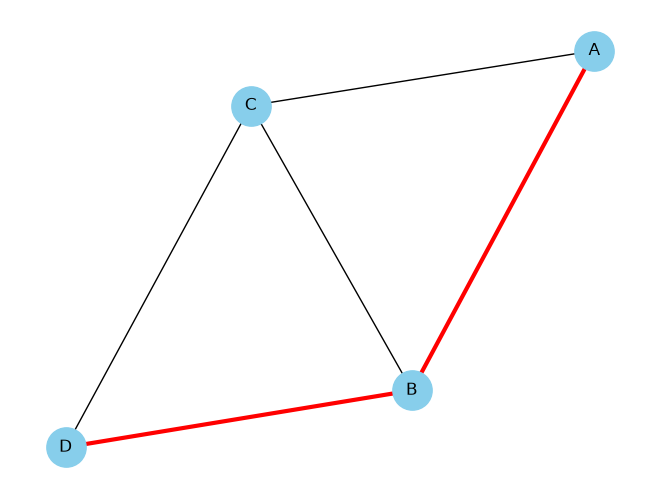

In [69]:
import matplotlib.pyplot as plt
import networkx as nx

pos = nx.spring_layout(G, seed=42)

path_edges = list(zip(path, path[1:]))

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color="skyblue",
    node_size=800
)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=path_edges,
    edge_color="red",
    width=3
)

plt.show()

#ML

In [71]:
import pandas as pd

traffic=pd.read_csv("../data/traffic.csv")
roads=pd.read_csv("../data/roads.csv")

In [72]:
traffic.head()

,time,weather,road_type,distance,actual_speed
0,8,Sunny,Highway,5,58
1,8,Rain,Highway,5,34
2,9,Cloudy,Street,3,28
3,10,Sunny,Main Road,4,46
4,11,Rain,Residential,2,20


In [73]:
roads.head()

,source,destination,distance,speed_limit,road_type
0,A,B,5,60,Highway
1,A,C,3,40,Street
2,A,D,4,50,Main Road
3,B,E,6,80,Highway
4,B,F,3,50,Street


In [74]:
traffic.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   time          20 non-null     int64
 1   weather       20 non-null     str  
 2   road_type     20 non-null     str  
 3   distance      20 non-null     int64
 4   actual_speed  20 non-null     int64
dtypes: int64(3), str(2)
memory usage: 1.2 KB


In [75]:
traffic.describe()

,time,distance,actual_speed
count,20.000000,20.000000,20.000000
mean,14.500000,4.200000,41.100000
std,5.114479,1.542384,16.945423
min,7.000000,2.000000,17.000000
25%,9.750000,3.000000,29.750000
50%,14.500000,4.500000,35.500000
75%,18.250000,5.000000,53.500000
max,23.000000,7.000000,76.000000


In [145]:
#x is for features
x=traffic[[
    "time", "weather","road_type","distance"]] 

In [146]:
x.head()

,time,weather,road_type,distance
0,8,Sunny,Highway,5
1,8,Rain,Highway,5
2,9,Cloudy,Street,3
3,10,Sunny,Main Road,4
4,11,Rain,Residential,2


In [147]:
#target is y
y=traffic["actual_speed"]

In [148]:
y.head()

0    58
1    34
2    28
3    46
4    20
Name: actual_speed, dtype: int64

In [149]:
x=pd.get_dummies(
    x,
    columns=["road_type","weather"]
)


In [150]:
x.head()

,time,distance,road_type_Highway,road_type_Main Road,road_type_Residential,road_type_Street,weather_Cloudy,weather_Rain,weather_Sunny
0,8,5,True,False,False,False,False,False,True
1,8,5,True,False,False,False,False,True,False
2,9,3,False,False,False,True,True,False,False
3,10,4,False,True,False,False,False,False,True
4,11,2,False,False,True,False,False,True,False


In [151]:
#split
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(
    x,y,
    test_size=0.2,
    random_state=42
)

In [87]:
#train

from sklearn.tree import DecisionTreeRegressor

model = DecisionTreeRegressor(
    random_state=42
)

model.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes 

In [89]:
#predict
prediction=model.predict(x_test)
prediction[:10]


array([60., 38., 31., 50.])

In [91]:
#compare
comparison=pd.DataFrame({
    "actual":y_test.values,
    "predicted":prediction
})
comparison["error"]=comparison["actual"]-comparison["predicted"]
comparison.head()

,actual,predicted,error
0,58,60.0,-2.0
1,36,38.0,-2.0
2,30,31.0,-1.0
3,34,50.0,-16.0


In [92]:
from sklearn.metrics import *
mae=mean_absolute_error(
    y_test,prediction
)
mae

5.25

In [99]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [103]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "KNN": KNeighborsRegressor()
}
models.items()

dict_items([('Linear Regression', LinearRegression()), ('Decision Tree', DecisionTreeRegressor(random_state=42)), ('Random Forest', RandomForestRegressor(random_state=42)), ('KNN', KNeighborsRegressor())])

In [101]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(
    x,y,
    test_size=0.2,
    random_state=42
)

In [105]:
for name, model in models.items():

    model.fit(x_train, y_train)

    predictions = model.predict(x_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = mse ** 0.5
    r2 = r2_score(y_test, predictions)

    print(f"\n{name}")
    print(f"MAE : {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R²  : {r2:.2f}")


Linear Regression
MAE : 11.48
RMSE: 14.37
R²  : -0.74

Decision Tree
MAE : 5.25
RMSE: 8.14
R²  : 0.44

Random Forest
MAE : 7.27
RMSE: 11.33
R²  : -0.08

KNN
MAE : 10.45
RMSE: 11.90
R²  : -0.19


In [106]:
f_model=DecisionTreeRegressor(random_state=42)
f_model.fit(x_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes 

In [110]:
from sklearn.metrics import mean_squared_error, r2_score

# 1. Get predictions from both regression models
preds_1 = model.predict(x_test)
preds_2 = f_model.predict(x_test)

# 2. Calculate Mean Squared Error (Lower is better)
mse_1 = mean_squared_error(y_test, preds_1)
mse_2 = mean_squared_error(y_test, preds_2)

# 3. Calculate R-Squared Score (Higher is better, 1.0 is perfect)
r2_1 = r2_score(y_test, preds_1)
r2_2 = r2_score(y_test, preds_2)

# 4. Print the comparison
print("=== Regression Model Comparison ===")
print(f"Model 1 -> MSE: {mse_1:.4f} | R2 Score: {r2_1:.4f}")
print(f"Model 2 -> MSE: {mse_2:.4f} | R2 Score: {r2_2:.4f}")

# 5. Automatically declare the winner
if r2_1 > r2_2:
    print("\nResult: Model 1 performed better!")
elif r2_2 > r2_1:
    print("\nResult: Model 2 performed better!")
else:
    print("\nResult: Both models performed identically.")


=== Regression Model Comparison ===
Model 1 -> MSE: 141.6100 | R2 Score: -0.1925
Model 2 -> MSE: 66.2500 | R2 Score: 0.4421

Result: Model 2 performed better!


In [111]:
row = {
    "time": 8,
    "distance": 5,
    "weather": "Rain",
    "road_type": "Highway"
}

row = pd.DataFrame([row])

print(row)

   time  distance weather road_type
0     8         5    Rain   Highway


In [112]:
row=pd.get_dummies(row)
row

,time,distance,weather_Rain,road_type_Highway
0,8,5,True,True


In [114]:
x_train.columns

Index(['time', 'distance', 'road_type_Highway', 'road_type_Main Road',
       'road_type_Residential', 'road_type_Street', 'weather_Cloudy',
       'weather_Rain', 'weather_Sunny'],
      dtype='str')

In [115]:
row.columns

Index(['time', 'distance', 'weather_Rain', 'road_type_Highway'], dtype='str')

In [117]:
row=row.reindex(
    columns=x_train.columns,
    fill_value=0
)
row

,time,distance,road_type_Highway,road_type_Main Road,road_type_Residential,road_type_Street,weather_Cloudy,weather_Rain,weather_Sunny
0,8,5,True,0,0,0,0,True,0


In [118]:
row.columns

Index(['time', 'distance', 'road_type_Highway', 'road_type_Main Road',
       'road_type_Residential', 'road_type_Street', 'weather_Cloudy',
       'weather_Rain', 'weather_Sunny'],
      dtype='str')

In [119]:
predict_speed=f_model.predict(row)[0]
predict_speed

np.float64(50.0)

In [125]:
def predict_speed(distance, road_type, time, weather):

    row = {
        "time": time,
        "distance": distance,
        "weather": weather,
        "road_type": road_type
    }

    row = pd.DataFrame([row])

    row = pd.get_dummies(row)

    row = row.reindex(
        columns=x_train.columns,
        fill_value=0
    )

    predicted_speed = f_model.predict(row)[0]

    return predicted_speed

In [126]:
speed = predict_speed(
    distance=5,
    road_type="Highway",
    time=8,
    weather="Rain"
)

print(speed)

50.0


In [127]:
print(predict_speed(5, "Highway", 8, "Sunny"))
print(predict_speed(5, "Highway", 8, "Rain"))
print(predict_speed(2, "Street", 18, "Rain"))

60.0
50.0
22.0


In [128]:
for u, v, data in G.edges(data=True):
    print(u, v, data)

A B {'distance': 5, 'speed_limit': 60, 'road_type': 'Highway', 'travel_time': 0.08333333333333333}
A C {'distance': 2, 'speed_limit': 30, 'road_type': 'Street', 'travel_time': 0.06666666666666667}
B D {'distance': 3, 'speed_limit': 80, 'road_type': 'Highway', 'travel_time': 0.0375}
B C {'distance': 6, 'speed_limit': 50, 'road_type': 'Main Road', 'travel_time': 0.12}
C D {'distance': 4, 'speed_limit': 40, 'road_type': 'Residential', 'travel_time': 0.1}


In [129]:
predicted_speed = predict_speed(
    distance=data["distance"],
    road_type=data["road_type"],
    time=8,
    weather="Rain"
)

In [130]:
data["travel_time"] = data["distance"] / predicted_speed

In [153]:
for u, v, data in G.edges(data=True):

    predicted_speed = predict_speed(
        distance=data["distance"],
        road_type=data["road_type"],
        time=8,
        weather="Rain"
    )

    data["travel_time"] = data["distance"] / predicted_speed

In [154]:
for u, v, data in G.edges(data=True):
    print(u, v, data)

A B {'distance': 5, 'speed_limit': 60, 'road_type': 'Highway', 'travel_time': np.float64(0.1)}
A C {'distance': 3, 'speed_limit': 40, 'road_type': 'Street', 'travel_time': np.float64(0.13636363636363635)}
A D {'distance': 4, 'speed_limit': 50, 'road_type': 'Main Road', 'travel_time': np.float64(0.10526315789473684)}
B E {'distance': 6, 'speed_limit': 80, 'road_type': 'Highway', 'travel_time': np.float64(0.07894736842105263)}
B F {'distance': 3, 'speed_limit': 50, 'road_type': 'Street', 'travel_time': np.float64(0.13636363636363635)}
C D {'distance': 2, 'speed_limit': 30, 'road_type': 'Residential', 'travel_time': np.float64(0.1)}
C G {'distance': 5, 'speed_limit': 40, 'road_type': 'Street', 'travel_time': np.float64(0.22727272727272727)}
D G {'distance': 4, 'speed_limit': 60, 'road_type': 'Main Road', 'travel_time': np.float64(0.10526315789473684)}
D H {'distance': 6, 'speed_limit': 80, 'road_type': 'Highway', 'travel_time': np.float64(0.07894736842105263)}
E F {'distance': 2, 'speed_l

In [155]:
path, cost = dijkstra(G, "A", "K")

print(path)
print(cost)

['A', 'D', 'H', 'K']
0.28421052631578947


In [156]:
G.nodes()

NodeView(('A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L'))

In [157]:
df_roads.tail()

,source,destination,distance,speed_limit,road_type
15,H,K,5,80,Highway
16,I,J,3,50,Street
17,I,L,6,60,Main Road
18,J,K,2,40,Residential
19,K,L,4,80,Highway


In [158]:
G.nodes()

NodeView(('A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L'))

In [159]:
G.edges()

EdgeView([('A', 'B'), ('A', 'C'), ('A', 'D'), ('B', 'E'), ('B', 'F'), ('C', 'D'), ('C', 'G'), ('D', 'G'), ('D', 'H'), ('E', 'F'), ('E', 'I'), ('F', 'G'), ('F', 'J'), ('G', 'H'), ('G', 'J'), ('H', 'K'), ('I', 'J'), ('I', 'L'), ('J', 'K'), ('K', 'L')])

In [160]:
G.edges(data=True)

EdgeDataView([('A', 'B', {'distance': 5, 'speed_limit': 60, 'road_type': 'Highway', 'travel_time': np.float64(0.1)}), ('A', 'C', {'distance': 3, 'speed_limit': 40, 'road_type': 'Street', 'travel_time': np.float64(0.13636363636363635)}), ('A', 'D', {'distance': 4, 'speed_limit': 50, 'road_type': 'Main Road', 'travel_time': np.float64(0.10526315789473684)}), ('B', 'E', {'distance': 6, 'speed_limit': 80, 'road_type': 'Highway', 'travel_time': np.float64(0.07894736842105263)}), ('B', 'F', {'distance': 3, 'speed_limit': 50, 'road_type': 'Street', 'travel_time': np.float64(0.13636363636363635)}), ('C', 'D', {'distance': 2, 'speed_limit': 30, 'road_type': 'Residential', 'travel_time': np.float64(0.1)}), ('C', 'G', {'distance': 5, 'speed_limit': 40, 'road_type': 'Street', 'travel_time': np.float64(0.22727272727272727)}), ('D', 'G', {'distance': 4, 'speed_limit': 60, 'road_type': 'Main Road', 'travel_time': np.float64(0.10526315789473684)}), ('D', 'H', {'distance': 6, 'speed_limit': 80, 'road_t